#  Text Classification — SMS Spam vs Ham

**A complete, beginner-friendly, step-by-step practical notebook** using the attached `spam.csv` (not synthetic data). Each step contains a small Python cell, its executed output, and an explanation. Follows the Chapter 4 lesson: preprocessing, Bag of Words, TF-IDF, Naive Bayes, Logistic Regression, Linear SVM, evaluation, and a prediction demo.

**Teaching and research notes:** The file has **5,574 rows** (not the 5,572-row UCI raw file used in some other examples). Treat this copy as the data source. We remove repeated rows before splitting, use TF-IDF inside model pipelines to avoid leakage, and evaluate on the same unseen test set. Random seed = 42.

## Step 1 — Import libraries

**Why:** Load the tools for data handling, visualization, machine learning, and saving the trained pipeline. `os`, `re`, `time`, etc. are useful in other projects, but import only what we actually need.

In [ ]:
import sys
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.metrics import make_scorer
import joblib
import sklearn


Python: 3.11.9
pandas: 2.2.3
scikit-learn: 1.8.0


## Step 2 — Load your CSV file

**Why:** `pd.read_csv()` reads the exact uploaded CSV. The notebook expects `data/spam.csv` in the project folder. Confirm that `text` and `label` exist before continuing.

In [43]:

df = pd.read_csv('./data/spam.csv')


## Step 3 — Show first 5 rows: `df.head()`

**Why:** Check that data was loaded correctly and observe actual SMS text and labels.

In [44]:
df.head()

,text,label
0,"Go until jurong point, crazy.. Available only ...",ham
1,Ok lar... Joking wif u oni...,ham
2,Free entry in 2 a wkly comp to win FA Cup fina...,spam
3,U dun say so early hor... U c already then say...,ham
4,"Nah I don't think he goes to usf, he lives aro...",ham


## Step 4 — Show last 5 rows: `df.tail()`

**Why:** Confirm that later rows are present and no unusual footer was parsed as data.

In [45]:
df.tail()

,text,label
5569,This is the 2nd time we have tried 2 contact u...,spam
5570,Will ü b going to esplanade fr home?,ham
5571,"Pity, * was in mood for that. So...any other s...",ham
5572,The guy did some bitching but I acted like i'd...,ham
5573,Rofl. Its true to its name,ham


## Step 5 — Dataset dimensions: `df.shape`

**Why:** `shape` is `(number_of_rows, number_of_columns)` before cleaning.

In [46]:
df.shape

(5574, 2)

In [47]:
df.shape[0]

5574

In [48]:
df.shape[1]

2

## Step 6 — Column names and types: `df.dtypes`

**Why:** Identify which feature is the message and which is the target label.

In [49]:
df.dtypes.to_frame(name="dtype")

,dtype
text,object
label,object


## Step 7 — Dataset summary: `df.info()`

**Why:** Check non-null counts and memory usage as shown in your screenshot.

In [50]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5574 entries, 0 to 5573
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    5574 non-null   object
 1   label   5574 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


## Step 8 — Descriptive statistics: `df.describe()`

**Why:** For text columns, `count`, `unique`, `top`, and `freq` describe the most common values—not numerical mean or standard deviation.

In [51]:
df.describe(include="all")

,text,label
count,5574,5574
unique,5171,2
top,"Sorry, I'll call later",ham
freq,30,4827


## Step 9 — Missing values: `isna()`

**Why:** Missing messages or missing labels cannot be used directly for supervised classification.

In [52]:
df.isna().sum().to_frame(name="missing_count")

,missing_count
text,0
label,0


## Step 10 — Label counts

**Why:** Compare `ham` (not spam) and `spam`. This task is imbalanced; accuracy alone will not be enough.

In [53]:
df['label'].value_counts()

label
ham     4827
spam     747
Name: count, dtype: int64

In [54]:
(df['label'].value_counts(normalize=True)*100).round(2).rename('percent').to_frame()

,percent
label,
ham,86.6
spam,13.4


## Step 11 — Check unexpected labels and blank messages

**Why:** Labels should be exactly `ham` or `spam`. Empty strings can appear even when `isna()` reports no missing values.

In [56]:
sorted(df['label'].astype(str).unique().tolist())


['ham', 'spam']

In [57]:
(~df['label'].isin(['ham','spam'])).sum()


0

In [58]:
df['text'].fillna('').astype(str).str.strip().eq('').sum()

0

## Step 12 — Duplicate rows

**Why:** Exact duplicates appearing in both training and testing would make evaluation too optimistic. Check duplication **before** the split.

In [ ]:
df.duplicated().sum() # Exact duplicate

403

In [ ]:
df.duplicated(subset=['text']).sum()  # Duplicate texts

403

## Step 13 — Check conflicting labels for the same text

**Why:** A repeated message with opposite labels may be an annotation error and should be inspected rather than silently discarded.

In [61]:
conflicts = df.groupby('text')['label'].nunique()
conflicting_texts = conflicts[conflicts > 1].index
print('Texts with conflicting labels:', len(conflicting_texts))
if len(conflicting_texts):
    display(df[df['text'].isin(conflicting_texts)].head(10))

Texts with conflicting labels: 0


## Step 14 — Clean the dataset

**Why:** Remove empty records and exact `(text,label)` duplicates, standardize the label spelling, and preserve original SMS text. We **do not** delete punctuation or numbers globally because these may be useful spam signals.

In [64]:
clean_df = df[['text', 'label']].dropna().copy()
clean_df['text'] = clean_df['text'].astype(str)
clean_df['label'] = clean_df['label'].astype(str).str.strip().str.lower()
clean_df = clean_df[clean_df['text'].str.strip().ne('')]
clean_df = clean_df[clean_df['label'].isin(['ham','spam'])]
clean_df = clean_df.drop_duplicates(subset=['text','label']).reset_index(drop=True)
print('Before cleaning:', len(df), 'rows')
print('After cleaning:', len(clean_df), 'rows')
print('Removed:', len(df)-len(clean_df), 'rows')
print(clean_df['label'].value_counts())

Before cleaning: 5574 rows
After cleaning: 5171 rows
Removed: 403 rows
label
ham     4518
spam     653
Name: count, dtype: int64


## Step 15 — Explore SMS message lengths

**Why:** Length is an exploratory feature. We calculate characters and words for visualization, but the classifiers below use text features only.

In [65]:
clean_df['char_count'] = clean_df['text'].str.len()
clean_df['word_count'] = clean_df['text'].str.split().str.len()
display(clean_df[['text','label','char_count','word_count']].head())
display(clean_df.groupby('label')[['char_count','word_count']].agg(['mean','median','max']).round(1))

,text,label,char_count,word_count
0,"Go until jurong point, crazy.. Available only ...",ham,111,20
1,Ok lar... Joking wif u oni...,ham,29,6
2,Free entry in 2 a wkly comp to win FA Cup fina...,spam,155,28
3,U dun say so early hor... U c already then say...,ham,49,11
4,"Nah I don't think he goes to usf, he lives aro...",ham,61,13


char_count             word_count            
            mean median  max       mean median  max
label                                              
ham         70.9   53.0  910       14.2   11.0  171
spam       137.7  148.0  223       23.7   25.0   35

## Step 16 — Plot the class distribution

**Why:** Visualize class imbalance from the *cleaned* dataset.

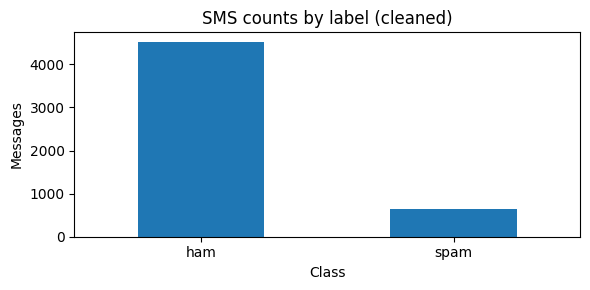

In [66]:
ax = clean_df['label'].value_counts().reindex(['ham','spam']).plot(kind='bar', figsize=(6,3), rot=0, title='SMS counts by label (cleaned)')
ax.set_xlabel('Class'); ax.set_ylabel('Messages'); plt.tight_layout(); plt.show()

## Step 17 — Plot message length

**Why:** Check whether spam and ham messages tend to have different lengths. An observation in a chart is not proof of causality.

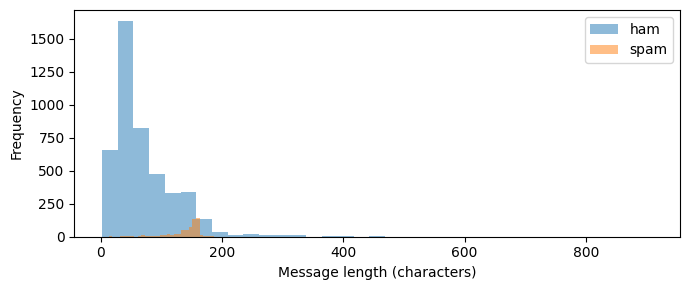

In [67]:
fig, ax = plt.subplots(figsize=(7,3))
for label in ['ham','spam']:
    ax.hist(clean_df.loc[clean_df.label.eq(label),'char_count'], bins=35, alpha=0.5, label=label)
ax.set_xlabel('Message length (characters)'); ax.set_ylabel('Frequency'); ax.legend(); plt.tight_layout(); plt.show()

## Step 18 — Text preprocessing demonstration

**Why:** Show lowercase conversion and tokenization on a real SMS. This is a *teaching illustration*, not an extra transformation applied to the classifier. `TfidfVectorizer` has its own tokenizer and lowercase handling.

In [68]:
example_text = clean_df.loc[2, 'text']
lowered = example_text.lower()
tokens = re.findall(r'(?u)\b\w+\b', lowered)
print('Original:', example_text)
print('Lowercase:', lowered)
print('Simple tokens:', tokens[:25])

Original: Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
Lowercase: free entry in 2 a wkly comp to win fa cup final tkts 21st may 2005. text fa to 87121 to receive entry question(std txt rate)t&c's apply 08452810075over18's
Simple tokens: ['free', 'entry', 'in', '2', 'a', 'wkly', 'comp', 'to', 'win', 'fa', 'cup', 'final', 'tkts', '21st', 'may', '2005', 'text', 'fa', 'to', '87121', 'to', 'receive', 'entry', 'question', 'std']


## Step 19 — Bag of Words: word-count example

**Why:** Bag of Words counts how frequently each token occurs. Here we use three illustrative messages, then apply TF-IDF to the full train/test data later.

In [69]:
toy_texts = ['free prize now', 'meeting now', 'free free offer']
count_vec = CountVectorizer()
count_features = count_vec.fit_transform(toy_texts)
display(pd.DataFrame(count_features.toarray(), columns=count_vec.get_feature_names_out(), index=['D1','D2','D3']))

,free,meeting,now,offer,prize
D1,1,0,1,0,1
D2,0,1,1,0,0
D3,2,0,0,1,0


## Step 20 — TF-IDF: weighted feature example

**Why:** TF-IDF reduces the relative weight of tokens appearing in many documents. This tiny example shows the numerical feature matrix.

In [70]:
toy_tfidf = TfidfVectorizer()
toy_matrix = toy_tfidf.fit_transform(toy_texts)
display(pd.DataFrame(toy_matrix.toarray(), columns=toy_tfidf.get_feature_names_out(), index=['D1','D2','D3']).round(3))

,free,meeting,now,offer,prize
D1,0.518,0.000,0.518,0.000,0.681
D2,0.000,0.796,0.605,0.000,0.000
D3,0.836,0.000,0.000,0.549,0.000


## Step 21 — Define features and target

**Why:** `X` is the SMS text and `y` is its known label. Keep descriptive columns, such as character count, out of the text-only model to preserve the lesson design.

In [71]:
X = clean_df['text']; y = clean_df['label']; print('X:', X.shape, 'y:', y.shape); print(y.value_counts())

X: (5171,) y: (5171,)
label
ham     4518
spam     653
Name: count, dtype: int64


## Step 22 — Train/test split (80/20, stratified)

**Why:** Separate the untouched test set **before fitting TF-IDF**. `stratify=y` preserves approximately the same spam percentage in train and test.

In [72]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print('Train messages:', len(X_train), 'Test messages:', len(X_test))
print('Train labels:'); print(y_train.value_counts())
print('Test labels:'); print(y_test.value_counts())
print('Overlap of exact SMS texts:', len(set(X_train).intersection(set(X_test))))

Train messages: 4136 Test messages: 1035
Train labels:
label
ham     3614
spam     522
Name: count, dtype: int64
Test labels:
label
ham     904
spam    131
Name: count, dtype: int64
Overlap of exact SMS texts: 0


## Step 23 — Configure three model pipelines

**Why:** Each pipeline fits `TfidfVectorizer` on the training fold only, then fits the classifier. This avoids train/test and cross-validation feature leakage. Identical TF-IDF settings give a fair comparison.

In [73]:
models = {
    'Naive Bayes': MultinomialNB(alpha=1.0),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Linear SVM': LinearSVC(random_state=42)
}
def make_pipeline(clf):
    return Pipeline([
        ('tfidf', TfidfVectorizer(lowercase=True, ngram_range=(1,2), min_df=2)),
        ('classifier', clf)
    ])
print('Models:', ', '.join(models))

Models: Naive Bayes, Logistic Regression, Linear SVM


## Step 24 — Train all three models

**Why:** Models are trained only with training messages. TF-IDF learns its vocabulary only from the respective training data.

In [74]:
import time
trained = {}
train_seconds = {}
for name, estimator in models.items():
    pipeline = make_pipeline(estimator)
    start = time.perf_counter()
    pipeline.fit(X_train, y_train)
    elapsed = time.perf_counter() - start
    trained[name] = pipeline
    train_seconds[name] = elapsed
    print(f'{name}: fitted; TF-IDF features={len(pipeline.named_steps["tfidf"].get_feature_names_out())}; time={elapsed:.3f}s')

Naive Bayes: fitted; TF-IDF features=10164; time=0.091s
Logistic Regression: fitted; TF-IDF features=10164; time=0.111s
Linear SVM: fitted; TF-IDF features=10164; time=0.087s


## Step 25 — Show the confusion matrix concept

**Why:** Confusion matrices distinguish errors: spam marked ham is a false negative (FN); ham marked spam is a false positive (FP). The positive class here is `spam`.

In [75]:
print('Rows = actual [ham, spam]; columns = predicted [ham, spam]')
print('[[TN, FP], [FN, TP]]')

Rows = actual [ham, spam]; columns = predicted [ham, spam]
[[TN, FP], [FN, TP]]


## Step 26 — Compare accuracy, precision, recall, F1

**Why:** Because spam is a minority class, rank models primarily by **spam F1** while also reporting precision and recall. The same untouched test set is used for all models.

In [76]:
metrics_rows = []
for name, model in trained.items():
    pred = model.predict(X_test)
    metrics_rows.append({
        'model': name,
        'accuracy': accuracy_score(y_test, pred),
        'spam_precision': precision_score(y_test, pred, pos_label='spam', zero_division=0),
        'spam_recall': recall_score(y_test, pred, pos_label='spam', zero_division=0),
        'spam_f1': f1_score(y_test, pred, pos_label='spam', zero_division=0),
        'training_seconds': train_seconds[name]
    })
results = pd.DataFrame(metrics_rows).sort_values('spam_f1', ascending=False).reset_index(drop=True)
display(results.round(4))

,model,accuracy,spam_precision,spam_recall,spam_f1,training_seconds
0,Linear SVM,0.9826,0.9829,0.8779,0.9274,0.0865
1,Naive Bayes,0.9633,1.0000,0.7099,0.8304,0.0911
2,Logistic Regression,0.9623,0.9894,0.7099,0.8267,0.1112


## Step 27 — Show classification reports

**Why:** A classification report includes precision, recall, F1 and support for **both** classes. `macro avg` gives classes equal weight; `weighted avg` weights by test class counts.

In [77]:
for name, model in trained.items():
    print('\n###', name)
    print(classification_report(y_test, model.predict(X_test), labels=['ham','spam'], zero_division=0))


### Naive Bayes
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       904
        spam       1.00      0.71      0.83       131

    accuracy                           0.96      1035
   macro avg       0.98      0.85      0.90      1035
weighted avg       0.96      0.96      0.96      1035


### Logistic Regression
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       904
        spam       0.99      0.71      0.83       131

    accuracy                           0.96      1035
   macro avg       0.97      0.85      0.90      1035
weighted avg       0.96      0.96      0.96      1035


### Linear SVM
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       904
        spam       0.98      0.88      0.93       131

    accuracy                           0.98      1035
   macro avg       0.98      0.94      0.96      1035
weighted avg    

## Step 28 — Display all three confusion matrices

**Why:** Observe how many legitimate messages each model falsely flags and how many spam messages each one misses.

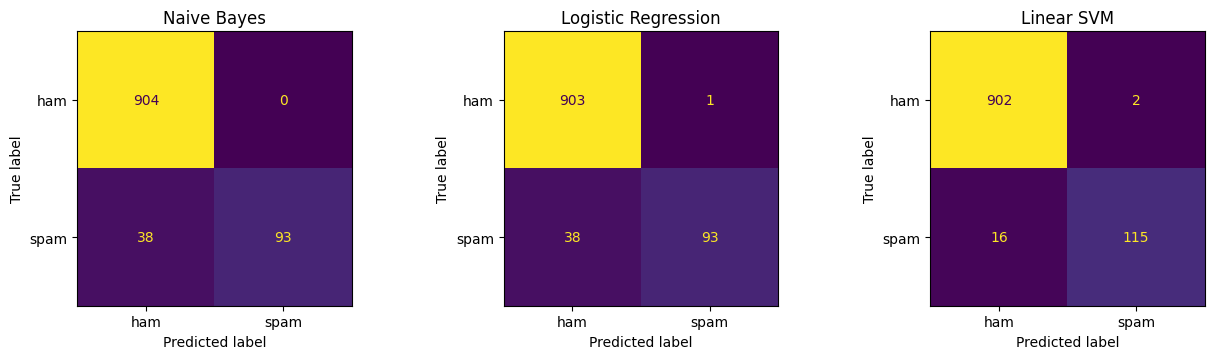

In [78]:
fig, axs = plt.subplots(1,3,figsize=(13,3.7))
for ax, (name, model) in zip(axs, trained.items()):
    cm = confusion_matrix(y_test, model.predict(X_test), labels=['ham','spam'])
    ConfusionMatrixDisplay(cm, display_labels=['ham','spam']).plot(ax=ax, colorbar=False, values_format='d')
    ax.set_title(name)
plt.tight_layout(); plt.show()

## Step 29 — Visual comparison of spam F1

**Why:** Compare spam F1 visually, not accuracy alone. The results depend on dataset version, cleaning decisions, train/test split and hyperparameters.

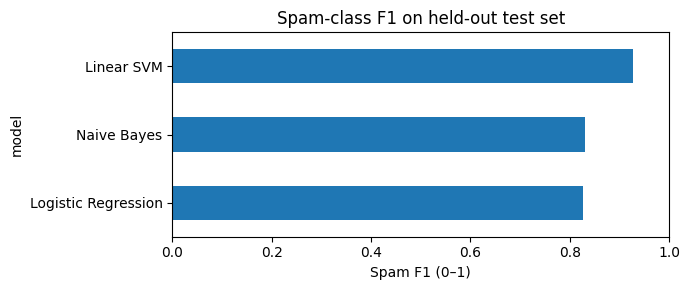

In [79]:
ax=results.set_index('model')['spam_f1'].sort_values().plot.barh(figsize=(7,3), xlim=(0,1), title='Spam-class F1 on held-out test set')
ax.set_xlabel('Spam F1 (0–1)'); plt.tight_layout(); plt.show()

## Step 30 — Cross-validation on training set only

**Why:** Check robustness of comparisons using 3 stratified training folds; the held-out test set is **not** part of CV. This step does not tune hyperparameters or claim statistical significance.

In [80]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
cv_rows=[]
for name, estimator in models.items():
    s = cross_validate(make_pipeline(estimator), X_train, y_train, cv=cv,
        scoring={'spam_f1':make_scorer(f1_score, pos_label='spam'),'accuracy':'accuracy'}, n_jobs=1)
    cv_rows.append({'model':name, 'cv_f1_mean':s['test_spam_f1'].mean(), 'cv_f1_std':s['test_spam_f1'].std(), 'cv_accuracy_mean':s['test_accuracy'].mean()})
cv_results=pd.DataFrame(cv_rows)
display(cv_results.round(4))

,model,cv_f1_mean,cv_f1_std,cv_accuracy_mean
0,Naive Bayes,0.7984,0.0153,0.9577
1,Logistic Regression,0.8127,0.0054,0.9601
2,Linear SVM,0.9464,0.0046,0.9869


## Step 31 — Identify the top model

**Why:** Select the largest measured spam F1 for this one split. For production, also consider ham false positives, operational cost, calibration and additional datasets.

In [81]:
best_name = results.loc[0,'model']; best_model=trained[best_name]; print('Best by held-out spam F1:', best_name); print('F1:', round(results.loc[0,'spam_f1'],4))

Best by held-out spam F1: Linear SVM
F1: 0.9274


## Step 32 — Predict your example SMS

**Why:** Send a **new message** directly into each fitted pipeline. Do not manually call the TF-IDF vectorizer: the pipeline performs the same training-time transformations.

In [82]:
sms = 'Congratulations! You have won a free prize. Claim it now!'
print('SMS:', sms)
for name, model in trained.items():
    print(f'{name:20s} -> {model.predict([sms])[0].upper()}')

SMS: Congratulations! You have won a free prize. Claim it now!
Naive Bayes          -> SPAM
Logistic Regression  -> SPAM
Linear SVM           -> SPAM


## Step 33 — Predict a normal (ham) SMS

**Why:** Try a legitimate-looking message. Classification is an estimate, not a guarantee of truth.

In [83]:
normal_sms = 'Hi, can we meet at the library after class tomorrow?'
print('SMS:', normal_sms)
for name, model in trained.items():
    print(f'{name:20s} -> {model.predict([normal_sms])[0].upper()}')

SMS: Hi, can we meet at the library after class tomorrow?
Naive Bayes          -> HAM
Logistic Regression  -> HAM
Linear SVM           -> HAM


## Step 34 — Predict several SMS messages in a table

**Why:** Demonstrate batch inference and inspect model disagreement. These are demonstration inputs, not test-set performance metrics.

In [84]:
new_messages = [
    'Congratulations! You have won a free prize. Claim it now!',
    'Hi, can we meet at the library after class tomorrow?',
    'URGENT! Reply WIN to claim your cash reward now!',
    'Please send me the homework before tonight.'
]
pred_table = pd.DataFrame({'text':new_messages})
for name, model in trained.items():
    pred_table[name] = model.predict(new_messages)
display(pred_table)

,text,Naive Bayes,Logistic Regression,Linear SVM
0,Congratulations! You have won a free prize. Cl...,spam,spam,spam
1,"Hi, can we meet at the library after class tom...",ham,ham,ham
2,URGENT! Reply WIN to claim your cash reward now!,spam,spam,spam
3,Please send me the homework before tonight.,ham,ham,ham


## Step 35 — Inspect important words in linear models

**Why:** Logistic Regression and Linear SVM assign positive/negative weights to TF-IDF features. These help interpretation but do **not** prove causal relationships.

In [85]:
linear = trained['Logistic Regression']
vocab = linear.named_steps['tfidf'].get_feature_names_out()
weights = linear.named_steps['classifier'].coef_[0]
positive_label = linear.named_steps['classifier'].classes_[1]
order = np.argsort(weights)
print('Positive-coefficient class:', positive_label)
print('Top positive terms:', vocab[order[-10:]][::-1].tolist())
print('Top negative terms:', vocab[order[:10]].tolist())

Positive-coefficient class: spam
Top positive terms: ['call', 'txt', 'free', 'text', 'to', 'reply', 'mobile', 'stop', 'www', 'your']
Top negative terms: ['my', 'me', 'that', 'ok', 'it', 'but', 'how', 'gt', 'lt', 'so']


## Step 36 — Save trained pipelines

**Why:** Each `.joblib` contains its fitted TF-IDF vectorizer **and** classifier, so inference uses the correct vocabulary. Load saved models only from trusted sources; joblib/pickle files can execute arbitrary code.

In [86]:
model_dir = Path('models'); model_dir.mkdir(exist_ok=True)
files = {}
for name, model in trained.items():
    f = model_dir / (name.lower().replace(' ','_') + '.joblib')
    joblib.dump(model, f)
    files[name] = f
    print('Saved:', f)

Saved: models\naive_bayes.joblib
Saved: models\logistic_regression.joblib
Saved: models\linear_svm.joblib


## Step 37 — Reload and verify predictions

**Why:** Confirm the saved pipeline predicts the same way after reloading. This is a basic model serialization smoke test.

In [87]:
loaded = joblib.load(files[best_name])  # Only load a file created locally in this notebook.
print('Model:', best_name)
print('Before saving:', best_model.predict([sms])[0])
print('After loading:', loaded.predict([sms])[0])
assert loaded.predict([sms])[0] == best_model.predict([sms])[0]

Model: Linear SVM
Before saving: spam
After loading: spam


## Step 38 — Export evaluation results

**Why:** Save a results table for slides, reports and comparison. The metrics are calculated from this run, not typed as constants.

In [88]:
report_dir=Path('reports'); report_dir.mkdir(exist_ok=True); results.to_csv(report_dir/'model_comparison.csv', index=False); cv_results.to_csv(report_dir/'cross_validation.csv',index=False); print('Saved:', report_dir/'model_comparison.csv', 'and', report_dir/'cross_validation.csv')

Saved: reports\model_comparison.csv and reports\cross_validation.csv


## Step 39 — Optional interactive input in Jupyter

**Why:** Uncomment the last two lines when running interactively. `input()` is disabled in this saved, fully executed notebook to avoid blocking automated execution.

In [89]:
def predict_sms(message: str):
    if not isinstance(message, str) or not message.strip():
        raise ValueError('Please enter a non-empty SMS message.')
    return {name: model.predict([message])[0] for name, model in trained.items()}
print(predict_sms('Free gift voucher! Reply now!'))
# custom_message = input('Enter SMS: ')
# print(predict_sms(custom_message))

{'Naive Bayes': 'spam', 'Logistic Regression': 'spam', 'Linear SVM': 'spam'}


## Step 40 — Conclusion and limitations

**How to interpret:** Compare spam-class precision, recall and F1, review confusion matrices, and explain why TF-IDF must fit on training data only. The held-out test set is used only for final evaluation; CV is restricted to the training set. **Limitations:** Short English SMS dataset; historical language; noisy labels; duplicates; possible message-template similarity; no external validation or calibration. No single split proves universal superiority. For a serious study, repeat the experiment across seeds or use nested CV and an external test set.

In [90]:
display(results[['model','accuracy','spam_precision','spam_recall','spam_f1']].round(4))
print('Completed: load → explore → clean → split → vectorize/train → evaluate → compare → predict → save')

,model,accuracy,spam_precision,spam_recall,spam_f1
0,Linear SVM,0.9826,0.9829,0.8779,0.9274
1,Naive Bayes,0.9633,1.0000,0.7099,0.8304
2,Logistic Regression,0.9623,0.9894,0.7099,0.8267


Completed: load → explore → clean → split → vectorize/train → evaluate → compare → predict → save
